In [1]:
%pylab inline
import fitsio
import treecorr
import numpy as np
import gc
import catutil

Populating the interactive namespace from numpy and matplotlib


In [36]:
data=fitsio.read('/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/WIDE12H_no_m.fits')

In [37]:
dataU=data[data['object_id']==42216990194032655]

In [197]:
dataU['i_hsmshaperegauss_derived_sigma_e']

array([0.05307861])

In [198]:
dataU['i_hsmshaperegauss_derived_rms_e']

array([0.3941625])

In [38]:
dataU['i_cmodel_flux']/dataU['i_cmodel_fluxerr']

array([83.26262], dtype=float32)

In [199]:
dataU['tract']

array([9599], dtype=int32)

In [201]:
iid=np.argmin(data['i_hsmshaperegauss_derived_sigma_e'])

In [204]:
data['i_cmodel_flux'][iid]/data['i_cmodel_fluxerr'][iid]

11642.451

In [155]:
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/XMM/mock_nres13_r003_rotmat10_shear_catalog.fits'
dataG   =   fitsio.read(os.path.join(catFname))
ra     =   dataG['ra_mock']
dec    =   dataG['dec_mock']
e1     =   dataG['shear1_sim']
e2     =   dataG['shear2_sim']
print(np.argmin(dataG['shear1_sim']))
ssPro=dataG[np.argmin(dataG['shear1_sim'])]
print(ssPro)
print(ssPro['z_source_mock'])

470433
(8522, 73562, 37480710713400375, 32.821, -5.499942, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, 0., -1.)
-1.0


In [156]:
dataG.dtype.names

('tract_id',
 'irow_in_original_fits_file',
 'object_id',
 'ra_mock',
 'dec_mock',
 'e1_mock',
 'e2_mock',
 'shear1_sim',
 'shear2_sim',
 'kappa',
 'noise1_int',
 'noise2_int',
 'noise1_mea',
 'noise2_mea',
 'weight',
 'z_source_mock')

In [16]:
def prepareCat(ver):
    if ver==0:
        pass
    elif ver==1:
        catFname='/work/xiangchong.li/work/S16ACatalogs/oguri_mock/mock_mlz_XMM_000.fits'
        dataG   =   fitsio.read(os.path.join(catFname))
        ra     =   dataG['ira']
        dec    =   dataG['idec']
        e1     =   dataG['mock_gamma1']
        e2     =   dataG['mock_gamma2']
    elif ver==2:
        catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/XMM/mock_nres13_r003_rotmat12_shear_catalog.fits'
        dataG   =   fitsio.read(os.path.join(catFname))
        mask   =   np.abs(dataG['shear1_sim'])<10
        dataG  =   dataG[mask]
        ra     =   dataG['ra_mock']
        dec    =   dataG['dec_mock']
        e1     =   dataG['shear1_sim']
        e2     =   dataG['shear2_sim']
    cat    =   treecorr.Catalog(g1=e1,g2=e2,ra=ra,dec=dec, ra_units='deg',dec_units='deg') 
    return cat
corGG1  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')

In [17]:
cat=prepareCat(ver=1)
corGG1.process(cat)
print(corGG.xip)

[4.95267034e-04 5.03640295e-04 4.88019649e-04 4.37979320e-04
 3.96426902e-04 3.36992592e-04 3.02337222e-04 2.44856250e-04
 1.98133612e-04 1.64449866e-04 1.38394693e-04 1.09287780e-04
 8.94752295e-05 7.01075964e-05 5.61449712e-05 4.54391896e-05
 3.74054888e-05 3.04910506e-05 2.47804047e-05 1.94197135e-05
 1.55372391e-05 1.10765980e-05 8.69122146e-06 6.53771377e-06
 4.13043191e-06 2.45513951e-06 2.08390947e-06 1.29666378e-06
 1.51051163e-06 1.14327745e-06]


In [18]:
cat=prepareCat(ver=2)
corGG1.process(cat)
print(corGG.xip)

[4.95267034e-04 5.03640295e-04 4.88019649e-04 4.37979320e-04
 3.96426902e-04 3.36992592e-04 3.02337222e-04 2.44856250e-04
 1.98133612e-04 1.64449866e-04 1.38394693e-04 1.09287780e-04
 8.94752295e-05 7.01075964e-05 5.61449712e-05 4.54391896e-05
 3.74054888e-05 3.04910506e-05 2.47804047e-05 1.94197135e-05
 1.55372391e-05 1.10765980e-05 8.69122146e-06 6.53771377e-06
 4.13043191e-06 2.45513951e-06 2.08390947e-06 1.29666378e-06
 1.51051163e-06 1.14327745e-06]


In [50]:
__outDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_compressed/'
for fieldname in catutil.field_names:
    data=fitsio.read('/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)
    __outFname=os.path.join(__outDir,'%s_weights.fits' %fieldname)
    fitsio.write(__outFname,data[['object_id','i_hsmshaperegauss_derived_weight']])

In [59]:
%timeit
wDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_compressed/'
fname   =   'mock_nres13_r003_rotmat12_shear_catalog.fits'
dataG   =   []
wG      =   []
for fieldname in catutil.field_names:
    wFname=os.path.join(wDir,'%s_weights.fits' %fieldname)
    weights=   fitsio.read(wFname)
    catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
    data   =   fitsio.read(os.path.join(catFname))
    assert np.all(data['object_id']==weights['object_id'])
    # selection
    mask   =   data['z_source_mock']>0.3
    mask   =   mask&(data['z_source_mock']<1.5)
    mask   =   mask&(data['e1_mock']**2.+data['e2_mock']**2.<10.)
    data   =   data[mask]
    weights=   weights[mask]['i_hsmshaperegauss_derived_weight']
    dataG.append(data)
    wG.append(weights)
    del data,mask
    gc.collect()
dataG=np.hstack(dataG)
wG=np.hstack(wG)

In [53]:
ra     =   dataG['ra_mock']
dec    =   dataG['dec_mock']
eI1    =   dataG['noise1_int']+dataG['noise1_mea']
eI2    =   dataG['noise2_int']+dataG['noise2_mea']
# define catalog
catE0  =   treecorr.Catalog(g1=eI1,g2=eI2,ra=ra,dec=dec,w=wG,ra_units='deg',dec_units='deg') 
catE1  =   treecorr.Catalog(g1=dataG['e1_mock'],g2=dataG['e2_mock'],w=wG,ra=ra,dec=dec,ra_units='deg',dec_units='deg') 
catG   =   treecorr.Catalog(g1=dataG['shear1_sim'],g2=dataG['shear2_sim'],w=wG,ra=ra,dec=dec,ra_units='deg',dec_units='deg') 
# 
corE0  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corE0.process(catE0)
corG   =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corG.process(catG)
corGE0 =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corGE0.process(catG,catE0)
corE1 =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corE1.process(catE1)
del dataG,catG,catE0,catE1
gc.collect()

responsivity: 0.8447668254375458


50

In [60]:
print('responsivity:',1-np.sum(wG*dataG['noise1_int']**2.)/np.sum(wG))

responsivity: 0.8471708463559333


Text(0, 0.5, '$\\xi^{+}$')

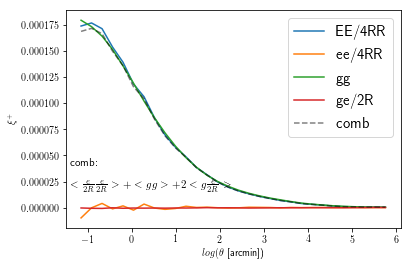

In [44]:
plt.close()
plt.plot(corE0.logr,corE1.xip/(2.*0.843)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xip/(2.*0.843)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xip,label='gg')
plt.plot(corE0.logr,corGE0.xip/(2.*0.843),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xip/(2.*0.843)+corE0.xip/(2.*0.843)**2.+corG.xip,label='comb',color='black',ls='--',alpha=0.5)
plt.text(-1.4,1.5e-5,r'$<\frac{e}{2R} \frac{e}{2R}>+ <g g> + 2<g \frac{e}{2R}>$',fontsize=11)
plt.text(-1.4,4e-5,'comb:',fontsize=11)
plt.legend(fontsize=15)
plt.xlabel(r'$log (\theta$ [arcmin])')
plt.ylabel(r'$\xi^{+}$')

Text(0, 0.5, '$\\xi^{+}$')

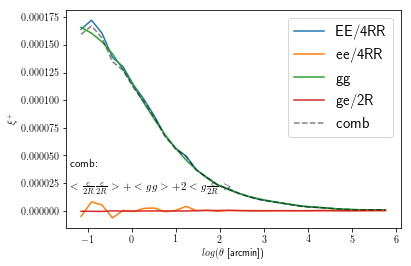

In [61]:
plt.close()
plt.plot(corE0.logr,corE1.xip/(2.*0.847)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xip/(2.*0.847)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xip,label='gg')
plt.plot(corE0.logr,corGE0.xip/(2.*0.847),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xip/(2.*0.847)+corE0.xip/(2.*0.847)**2.+corG.xip,label='comb',color='black',ls='--',alpha=0.5)
plt.text(-1.4,1.5e-5,r'$<\frac{e}{2R} \frac{e}{2R}>+ <g g> + 2<g \frac{e}{2R}>$',fontsize=11)
plt.text(-1.4,4e-5,'comb:',fontsize=11)
plt.legend(fontsize=15)
plt.xlabel(r'$log (\theta$ [arcmin])')
plt.ylabel(r'$\xi^{+}$')

Text(0, 0.5, '$\\xi^{-}$')

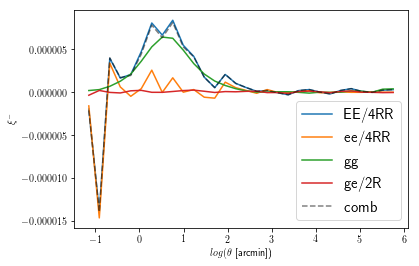

In [45]:
plt.close()
plt.plot(corE0.logr,corE1.xim/(2.*0.843)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xim/(2.*0.843)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xim,label='gg')
plt.plot(corE0.logr,corGE0.xim/(2.*0.843),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xim/(2.*0.843)+corE0.xim/(2.*0.843)**2.+corG.xim,label='comb',color='black',ls='--',alpha=0.5)
plt.legend(fontsize=15)
plt.xlabel(r'$log(\theta$ [arcmin])')
plt.ylabel(r'$\xi^{-}$')

Text(0, 0.5, '$\\xi^{-}$')

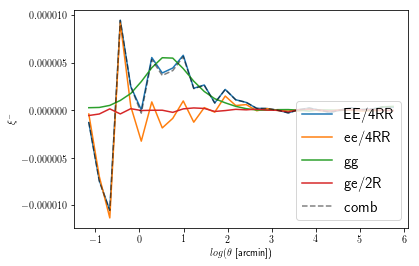

In [62]:
plt.close()
plt.plot(corE0.logr,corE1.xim/(2.*0.847)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xim/(2.*0.847)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xim,label='gg')
plt.plot(corE0.logr,corGE0.xim/(2.*0.847),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xim/(2.*0.847)+corE0.xim/(2.*0.847)**2.+corG.xim,label='comb',color='black',ls='--',alpha=0.5)
plt.legend(fontsize=15,loc='lower right')
plt.xlabel(r'$log(\theta$ [arcmin])')
plt.ylabel(r'$\xi^{-}$')

In [64]:
outFname='E1cor.csv'
corE1.write(outFname)

In [33]:
fieldname='WIDE12H'
fname   =   'mock_nres13_r003_rotmat12_shear_catalog.fits'
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
data   =   fitsio.read(os.path.join(catFname))

In [34]:
dataU=data[data['object_id']==42216990194032655]